<a href="https://colab.research.google.com/github/mhabibier/Practical-Statistics-for-Data-Scientists/blob/main/06_Statistical_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mhabibier/Practical-Statistics-for-Data-Scientists/blob/main/06_Statistical_Machine_Learning.ipynb)

# Chapter 6 — Statistical Machine Learning

**Buku:** *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, edisi kedua (2020), Peter Bruce, Andrew Bruce, Peter Gedeck, O'Reilly Media.  
**Mahasiswa:** Muhammad Habibie Rabbani · TK-47-04 · Teknik Komputer, Telkom University.  
**Jenis pekerjaan:** reproduksi/adaptasi kode pendamping resmi, penjelasan teori berbahasa Indonesia, dan analisis tambahan.  
**Sumber kode:** [repository penulis pada commit tetap](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/8a6d3bb6468e979c861d4b37215e1413702dfdfa); hak cipta kode sumber © 2019 Peter C. Bruce, Andrew Bruce, Peter Gedeck, GPL-3.0 (lihat `LICENSE` dan `THIRD_PARTY_NOTICES.md`).

Jalankan setiap sel dari atas ke bawah dalam sesi baru. Output disertakan sebagai contoh hasil aktual, bukan angka yang wajib diperoleh semua versi. Bagian berlabel **reproduksi eksploratif** mempelajari pola pada data buku; bagian **evaluasi prediktif** memakai data yang dipisahkan. Penjelasan dan kode disusun dengan bantuan LLM, diperiksa serta dieksekusi; mahasiswa perlu menelaah, menjalankan ulang, dan menuliskan refleksi sendiri.

## Tujuan dan cakupan

Chapter ini membandingkan pembelajaran lokal (KNN), aturan rekursif (tree), averaging bootstrap (bagging/random forest), dan boosting. Setiap algoritme dijelaskan bersama alasan preprocessing, kompleksitas, bias–variance, serta evaluasinya.

| Bagian buku | Reproduksi / adaptasi |
|---|---|
| KNN, distance, one-hot, standardisasi, memilih k | loan200, perbandingan tetangga mentah/standar, training CV |
| KNN sebagai feature engine | Fitur skor dibentuk out-of-fold; contoh in-sample ditandai berisiko |
| Tree, partitioning, impurity, stopping, regresi | Entropy tree loan3000, plot batas dan pohon, impurity curves, contoh regresi |
| Bagging/random forest, OOB, importance, hyperparameters | OOB learning curve, tuning, permutation importance pada validation |
| Boosting, XGBoost, regularisasi, cross-validation | Reproduksi dua fitur, kurva train/validation, grid search dan final test |

Contoh sumber yang memakai borrower_score disajikan sebagai ilustrasi. Benchmark utama tidak memakai skor yang telah dibentuk sebelumnya. Parameter pencarian dan jumlah model dikurangi secara eksplisit agar praktis dijalankan pada CPU; konsep dan semua keluarga metode tetap tercakup.

## Persiapan lingkungan dan data

Python 3.12 digunakan saat pengujian. Sel berikut memasang pustaka tambahan hanya bila belum tersedia. Instalasi pertama memerlukan internet; jika lingkungan sudah siap, semua data tersedia dalam folder `data/` paket ZIP. Jika notebook dibuka sendiri di Colab, pembaca data mengunduh versi resmi yang dipatok pada commit tertentu dan memeriksa SHA-256. Tidak ada penggantian otomatis dengan data sintetis. `requirements-tested.txt` mencatat versi pengujian.

In [1]:
import importlib.util, importlib.metadata, subprocess, sys
required = {'xgboost': 'xgboost>=2,<4'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
import sklearn
SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10})
pd.set_option("display.max_columns", 24)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
%matplotlib inline

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, log_loss, ConfusionMatrixDisplay,
    mean_absolute_error, r2_score, precision_recall_curve)
from xgboost import XGBClassifier
from matplotlib.patches import Ellipse
print("XGBoost",importlib.metadata.version("xgboost"))

Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | sklearn 1.6.1
XGBoost 3.4.1


In [2]:
import urllib.request, hashlib
SOURCE_COMMIT = '8a6d3bb6468e979c861d4b37215e1413702dfdfa'
EXPECTED_SHA256 = {'loan200.csv': '20fa74aa858a19893d09f70e39d7fc1020dacfabead29a561136b07b554ba320', 'loan3000.csv': '64dcaf1c93d611a45276966bf9601201f47919136a7ecf375a60e74025a532f2', 'loan_data.csv.gz': 'de10007e08c98cbe563c88711fde73ccdc882474544a7e5c3d2d22a2cda6d7e1', 'full_train_set.csv.gz': '8e28117e1933b3ccda73b7415ceb438c951ff3cc7fd1c83a621e160d9c00a7eb', 'sp500_data.csv.gz': 'fb86ce1a70897800bee406a3c004254a731231041bb17aa4624e5fc3ab31cea7', 'sp500_sectors.csv': 'd4cfd1329b16aa5cbab7aeaaadbed2e21c0e78835d39aeb58abc58f1762cc337', 'housetasks.csv': '0adb7e7e50f387621e54ac572df5738da54ac66080b3b3f8b7c000d2c89393e7', 'sp500_18_stocks.csv.gz': '81f259c5909a75f96bbb3544739b88fec3c2125bc5867ce811c80582a3fd2150'}
DATA = Path("data")
DATA.mkdir(exist_ok=True)
STOCKS = sorted(["GOOGL", "AMZN", "AAPL", "MSFT", "CSCO", "INTC", "CVX", "XOM", "SLB", "COP", "JPM", "WFC", "USB", "AXP", "WMT", "TGT", "HD", "COST"])
def load_data(name, **kwargs):
    path = DATA / name
    if not path.exists():
        if name == "sp500_18_stocks.csv.gz":
            original = load_data("sp500_data.csv.gz", index_col=0)
            # Preserve all observations, select only the 18 symbols used in Chapter 7.
            return original.loc[:, STOCKS].copy()
        url = f"https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/{SOURCE_COMMIT}/data/{name}"
        with urllib.request.urlopen(url, timeout=120) as response:
            payload = response.read()
        if hashlib.sha256(payload).hexdigest() != EXPECTED_SHA256[name]:
            raise ValueError(f"Checksum tidak cocok untuk {name}")
        path.write_bytes(payload)
    observed = hashlib.sha256(path.read_bytes()).hexdigest()
    if observed != EXPECTED_SHA256[name]:
        raise ValueError(f"Berkas lokal {name} berbeda dari versi yang diuji")
    return pd.read_csv(path, **kwargs)

def audit_frame(frame, name, target=None):
    print(f"{name}: {len(frame):,} baris × {frame.shape[1]} kolom")
    print("Missing:", int(frame.isna().sum().sum()), "| duplikasi semua kolom:", int(frame.duplicated().sum()))
    if target:
        display(frame[target].value_counts(dropna=False).rename("jumlah").to_frame().assign(proporsi=lambda x: x.jumlah / len(frame)))

## 1. Data, target, dan risiko leakage

`loan200` berisi 200 contoh berlabel serta satu baris `target` yang akan diprediksi. `target` bukan kelas ketiga dan tidak memiliki label aktual untuk menghitung akurasi. `loan3000` dipakai untuk gambar dua dimensi. `loan_data` mempunyai 45.342 contoh dengan proporsi kelas yang sudah diseimbangkan oleh penulis.

Target positif ditetapkan `default=1`. `status` dan ID dikeluarkan. `borrower_score` hasil pembentukan sebelumnya tidak digunakan pada benchmark karena pembentukannya melibatkan label dan tidak menjamin isolasi terhadap split kita. Chapter ini membuat versi fitur KNN yang lebih aman melalui out-of-fold prediction.

Kinerja pinjaman historis dengan random split hanya mendukung eksperimen pada sampel ini. Tanpa identitas peminjam dan urutan pemberian pinjaman, independensi antarorang dan generalisasi temporal belum teruji.

In [3]:
loan200=load_data("loan200.csv")
small=load_data("loan3000.csv")
loan=load_data("loan_data.csv.gz")
for name,df in [("loan200",loan200),("loan3000",small),("loan_data",loan)]:audit_frame(df,name,"outcome")
assert loan200.iloc[0].outcome=="target"
small["default"]=small.outcome.eq("default").astype(int)
loan["default"]=loan.outcome.eq("default").astype(int)

loan200: 201 baris × 3 kolom
Missing: 0 | duplikasi semua kolom: 0


,jumlah,proporsi
outcome,,
paid off,104,0.517413
default,96,0.477612
target,1,0.004975


loan3000: 3,000 baris × 6 kolom
Missing: 0 | duplikasi semua kolom: 0


,jumlah,proporsi
outcome,,
paid off,1555,0.518333
default,1445,0.481667


loan_data: 45,342 baris × 21 kolom
Missing: 0 | duplikasi semua kolom: 0


,jumlah,proporsi
outcome,,
default,22671,0.5
paid off,22671,0.5


## 2. K-nearest neighbors: voting dan jarak

KNN menyimpan data training, mencari k tetangga, lalu melakukan voting. Estimasi probabilitas sederhana adalah proporsi kelas positif di tetangga; `weights="distance"` memberi bobot lebih besar pada yang dekat. Nilai k kecil fleksibel tetapi varians tinggi; k besar lebih halus tetapi dapat mengabaikan pola lokal. Memilih k harus memakai CV training.

Minkowski: $d_p(x,z)=(\sum_j|x_j-z_j|^p)^{1/p}$. Manhattan memakai $p=1$, Euclidean $p=2$. KNN peka terhadap satuan, outlier, serta banyak fitur tidak relevan (*curse of dimensionality*). Standardisasi $z=(x-\mu_{train})/\sigma_{train}$ mencegah fitur berskala rupiah/dolar mendominasi fitur rasio.

Kategori nominal tidak memiliki urutan alami. One-hot menghindari urutan palsu, tetapi kategori dengan banyak level dapat mengubah geometri jarak. Scaling indikator jarang juga dapat memberi bobot sangat besar; preprocessing harus dipilih sesuai arti jarak yang diinginkan.

,default,paid off
target tanpa label aktual,0.45,0.55


Voting: paid off


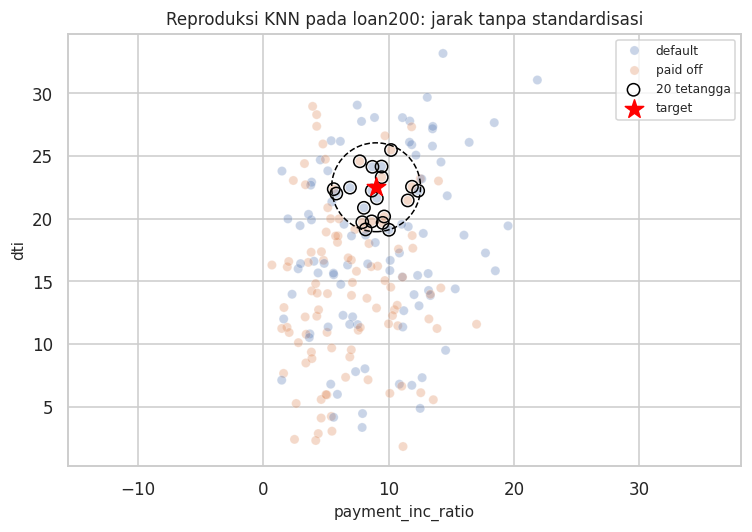

In [4]:
cols=["payment_inc_ratio","dti"]
newloan=loan200.iloc[[0]][cols]
knn_example=KNeighborsClassifier(n_neighbors=20).fit(loan200.iloc[1:][cols],loan200.iloc[1:].outcome)
dist,idx=knn_example.kneighbors(newloan)
display(pd.DataFrame(knn_example.predict_proba(newloan),columns=knn_example.classes_,index=["target tanpa label aktual"]))
print("Voting:",knn_example.predict(newloan)[0])
neighbors=loan200.iloc[1:].iloc[idx[0]]
fig,ax=plt.subplots(figsize=(7,5))
sns.scatterplot(data=loan200.iloc[1:],x=cols[0],y=cols[1],hue="outcome",alpha=.3,ax=ax)
ax.scatter(neighbors[cols[0]],neighbors[cols[1]],s=65,facecolors="none",edgecolors="black",label="20 tetangga")
ax.scatter(newloan[cols[0]],newloan[cols[1]],marker="*",s=160,c="red",label="target")
ax.add_patch(Ellipse(newloan.iloc[0].to_numpy(),2*dist.max(),2*dist.max(),fill=False,ls="--",color="black"))
ax.set_aspect("equal",adjustable="datalim");ax.legend(fontsize=8);ax.set_title("Reproduksi KNN pada loan200: jarak tanpa standardisasi")
plt.tight_layout();plt.show()

In [5]:
numeric4=["payment_inc_ratio","dti","revol_bal","revol_util"]
reference_X=loan.iloc[1:][numeric4]
query=loan.iloc[[0]][numeric4]
raw_knn=KNeighborsClassifier(n_neighbors=5).fit(reference_X,loan.iloc[1:].default)
raw_ids=raw_knn.kneighbors(query,return_distance=False)[0]
scaler=StandardScaler().fit(reference_X)
scaled_knn=KNeighborsClassifier(n_neighbors=5).fit(scaler.transform(reference_X),loan.iloc[1:].default)
scaled_ids=scaled_knn.kneighbors(scaler.transform(query),return_distance=False)[0]
display(query)
print("Tetangga tanpa scaling");display(reference_X.iloc[raw_ids])
print("Tetangga dengan scaling training");display(reference_X.iloc[scaled_ids])
print("Tetangga yang sama:",len(set(raw_ids)&set(scaled_ids)),"dari 5")
a=np.array([0.,0.]);z=np.array([3.,4.])
print("Contoh jarak Manhattan:",np.abs(a-z).sum(),"Euclidean:",np.linalg.norm(a-z))

,payment_inc_ratio,dti,revol_bal,revol_util
0,2.3932,1.0,1687,9.4


Tetangga tanpa scaling


,payment_inc_ratio,dti,revol_bal,revol_util
35536,1.47212,1.46,1686,10.0
33651,3.38178,6.37,1688,8.4
25863,2.36303,1.39,1691,3.5
42953,1.28160,7.14,1684,3.9
43599,4.12244,8.98,1684,7.2


Tetangga dengan scaling training


,payment_inc_ratio,dti,revol_bal,revol_util
2080,2.61091,1.03,1218,9.7
1438,2.34343,0.51,278,9.9
30215,2.71200,1.34,1075,8.5
28542,2.39760,0.74,2917,7.4
44737,2.34309,1.37,488,7.2


Tetangga yang sama: 0 dari 5
Contoh jarak Manhattan: 7.0 Euclidean: 5.0


### 2.1 Rancangan benchmark dan tuning KNN

Gunakan maksimum 16.000 baris yang diambil secara stratified dan seed tetap dari dataset buku, kemudian split 60/20/20. `MAX_ROWS=None` dapat dipakai untuk menjalankan seluruh data; hasil dan waktu akan berubah. Sampel dibatasi demi waktu komputasi, bukan dipilih berdasarkan skor. Median imputation tetap ada sebagai prosedur yang aman bila data baru memiliki missing value, walaupun data buku sudah bersih.

Numerik di-scale untuk KNN; one-hot kategori dibiarkan sebagai indikator 0/1. Pada tree/forest/boosting standardisasi numerik tidak diperlukan karena keputusan ambang tidak bergantung pada perubahan skala monoton. Kandidat dipilih dengan AP pada CV training; validation membandingkan keluarga algoritme.

In [6]:
NUM=["loan_amnt","annual_inc","dti","payment_inc_ratio","revol_bal","revol_util","delinq_2yrs_zero","pub_rec_zero","open_acc","grade","emp_length"]
CAT=["term","purpose_","home_","emp_len_"]
FEATURES=NUM+CAT
frame=loan[FEATURES+["default"]].drop_duplicates().copy()
MAX_ROWS=16000
if MAX_ROWS is not None and len(frame)>MAX_ROWS:
    frame,_=train_test_split(frame,train_size=MAX_ROWS,stratify=frame.default,random_state=SEED)
X_train,X_hold,y_train,y_hold=train_test_split(frame[FEATURES],frame.default,test_size=.4,stratify=frame.default,random_state=SEED)
X_val,X_test,y_val,y_test=train_test_split(X_hold,y_hold,test_size=.5,stratify=y_hold,random_state=SEED)
for a,c in [(X_train,X_val),(X_train,X_test),(X_val,X_test)]:
    assert not (set(pd.util.hash_pandas_object(a,index=False)) & set(pd.util.hash_pandas_object(c,index=False)))
display(pd.DataFrame({"split":["train","validation","test"],"n":[len(y_train),len(y_val),len(y_test)],"default_rate":[y_train.mean(),y_val.mean(),y_test.mean()]}))
continuous=[c for c in NUM if c not in ["delinq_2yrs_zero","pub_rec_zero"]]
q1,q3=X_train[continuous].quantile(.25),X_train[continuous].quantile(.75)
display(((X_train[continuous]<q1-1.5*(q3-q1))|(X_train[continuous]>q3+1.5*(q3-q1))).sum().rename("flag_IQR_training").to_frame())
def preprocessing(scale=False):
    numeric=make_pipeline(SimpleImputer(strategy="median"),StandardScaler()) if scale else SimpleImputer(strategy="median")
    return ColumnTransformer([("numeric",numeric,NUM),("categorical",OneHotEncoder(handle_unknown="ignore",sparse_output=False),CAT)])
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
knn_search=GridSearchCV(Pipeline([("preprocess",preprocessing(True)),("model",KNeighborsClassifier())]),
    {"model__n_neighbors":[7,21,51],"model__weights":["uniform","distance"]},cv=cv,scoring="average_precision",n_jobs=1)
knn_search.fit(X_train,y_train)
display(pd.DataFrame(knn_search.cv_results_)[["param_model__n_neighbors","param_model__weights","mean_test_score","std_test_score"]].sort_values("mean_test_score",ascending=False))

,split,n,default_rate
0,train,9600,0.5
1,validation,3200,0.5
2,test,3200,0.5


,flag_IQR_training
loan_amnt,301
annual_inc,469
dti,1
payment_inc_ratio,35
revol_bal,477
revol_util,0
open_acc,184
grade,34
emp_length,0


,param_model__n_neighbors,param_model__weights,mean_test_score,std_test_score
5,51,distance,0.650731,0.010637
4,51,uniform,0.644712,0.009881
3,21,distance,0.640472,0.009180
2,21,uniform,0.628990,0.008196
1,7,distance,0.615128,0.008153
0,7,uniform,0.597359,0.007669


### 2.2 KNN sebagai pembentuk fitur: out-of-fold

Skor tetangga dapat merangkum beberapa variabel menjadi sebuah fitur untuk model berikutnya. Jika label setiap baris ikut menentukan fiturnya sendiri atau fitur baris yang dipakai mengevaluasi model, skor dapat terlalu optimistis. Untuk training, kita menghasilkan probabilitas dari model yang **tidak pernah dilatih pada baris tersebut** melalui cross-fitting. Untuk validation/test, skor dibuat oleh model yang dilatih hanya pada training.

Ini setara ide stacking. Preprocessor juga dilatih ulang dalam setiap fold. Setelah menghasilkan fitur OOF, jangan menjalankan CV baru sembarangan pada tabel yang sudah ditambah fitur tersebut: seluruh pembentukan fitur perlu diulang di dalam outer fold. Contoh berikut memakai holdout validation untuk perbandingan, bukan mengklaim CV meta-model yang bebas leakage.

AP validation tanpa fitur KNN: 0.6357
AP validation dengan fitur KNN OOF: 0.6359
Fitur OOF berupa probabilitas paid off; tidak sama dengan label aktual.


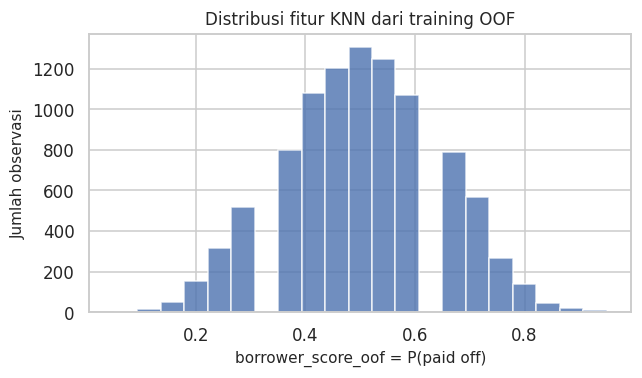

In [7]:
engine_cols=["dti","revol_bal","revol_util","open_acc","delinq_2yrs_zero","pub_rec_zero"]
engine=make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),KNeighborsClassifier(n_neighbors=20))
oof_default=cross_val_predict(engine,X_train[engine_cols],y_train,cv=cv,method="predict_proba",n_jobs=1)[:,1]
engine.fit(X_train[engine_cols],y_train)
train_aug=X_train[NUM].copy();val_aug=X_val[NUM].copy()
train_aug["borrower_score_oof"]=1-oof_default
val_aug["borrower_score_oof"]=1-engine.predict_proba(X_val[engine_cols])[:,1]
meta=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)).fit(train_aug,y_train)
base_numeric=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)).fit(X_train[NUM],y_train)
print("AP validation tanpa fitur KNN:",round(average_precision_score(y_val,base_numeric.predict_proba(X_val[NUM])[:,1]),4))
print("AP validation dengan fitur KNN OOF:",round(average_precision_score(y_val,meta.predict_proba(val_aug)[:,1]),4))
print("Fitur OOF berupa probabilitas paid off; tidak sama dengan label aktual.")
fig,ax=plt.subplots(figsize=(6,3.6))
ax.hist(1-oof_default,bins=21,alpha=.8)
ax.set(xlabel="borrower_score_oof = P(paid off)",ylabel="Jumlah observasi",title="Distribusi fitur KNN dari training OOF")
plt.tight_layout();plt.show()

## 3. Tree: recursive partitioning dan impurity

Tree memilih fitur dan ambang yang memisahkan data menjadi kelompok lebih homogen, lalu mengulang pada anak node. Untuk proporsi kelas $p_k$, Gini $=1-\sum_k p_k^2$, entropy $=-\sum_k p_k\log_2p_k$, dan classification error $=1-\max_kp_k$. Split menurunkan impurity parent dikurangi rata-rata tertimbang impurity anak. Gini dan entropy lebih peka terhadap perubahan distribusi dibanding classification error.

Kedalaman, minimum sampel daun, minimum impurity decrease, atau cost-complexity pruning menghentikan pertumbuhan. Tree terlalu dalam dapat menghafal noise; tree dangkal dapat underfit. Aturan pohon mudah dilihat, tetapi perubahan kecil pada data dapat mengubah struktur. Leaf classifier memberi proporsi kelas training dalam daun, bukan kepastian kebenaran. Pada regresi, daun umumnya memprediksi rerata target, dan split mengurangi squared error.

Plot buku diadaptasi memakai ambang dari model aktual, bukan angka batas yang diketik manual dari run lain.

|--- borrower_score <= 0.58
|   |--- borrower_score <= 0.33
|   |   |--- class: 1
|   |--- borrower_score >  0.33
|   |   |--- payment_inc_ratio <= 10.42
|   |   |   |--- class: 0
|   |   |--- payment_inc_ratio >  10.42
|   |   |   |--- class: 1
|--- borrower_score >  0.58
|   |--- payment_inc_ratio <= 9.19
|   |   |--- borrower_score <= 0.72
|   |   |   |--- class: 0
|   |   |--- borrower_score >  0.72
|   |   |   |--- class: 0
|   |--- payment_inc_ratio >  9.19
|   |   |--- class: 0



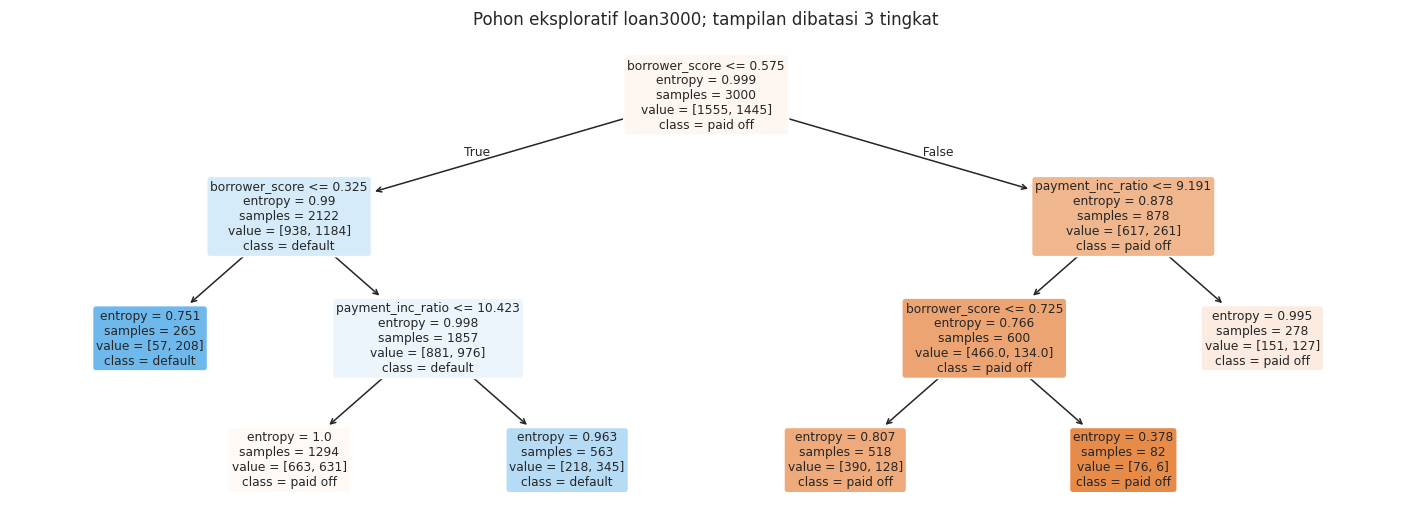

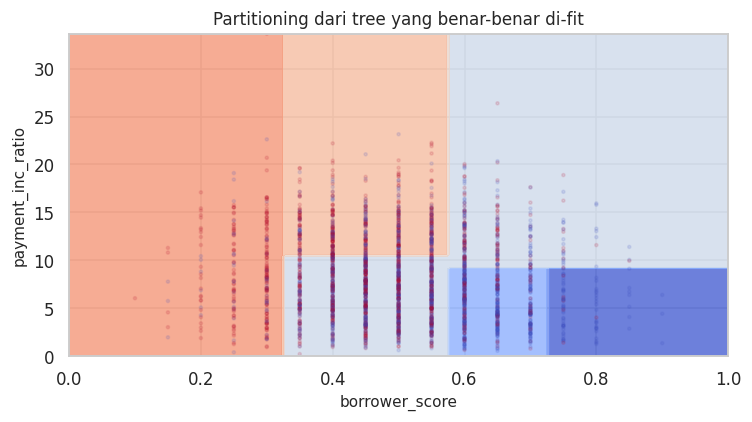

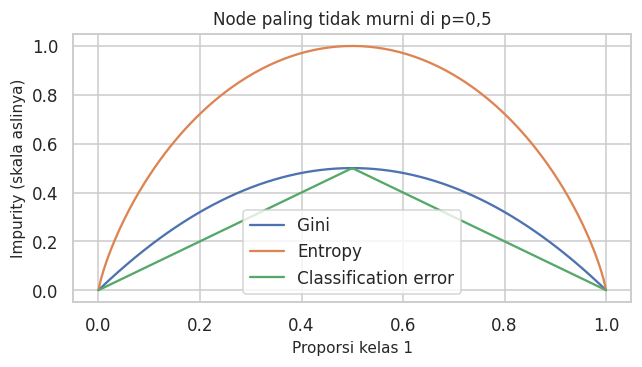

In [8]:
two=["borrower_score","payment_inc_ratio"]
tree_book=DecisionTreeClassifier(criterion="entropy",min_impurity_decrease=.003,random_state=SEED).fit(small[two],small.default)
print(export_text(tree_book,feature_names=two,max_depth=3))
fig,ax=plt.subplots(figsize=(13,5))
plot_tree(tree_book,feature_names=two,class_names=["paid off","default"],max_depth=3,filled=True,rounded=True,fontsize=8,ax=ax)
ax.set_title("Pohon eksploratif loan3000; tampilan dibatasi 3 tingkat")
plt.tight_layout();plt.show()
gx,gy=np.meshgrid(np.linspace(0,1,160),np.linspace(0,max(25,small.payment_inc_ratio.max()),160))
grid=pd.DataFrame({two[0]:gx.ravel(),two[1]:gy.ravel()})
fig,ax=plt.subplots(figsize=(7,4))
ax.contourf(gx,gy,tree_book.predict_proba(grid)[:,1].reshape(gx.shape),levels=np.linspace(0,1,11),cmap="coolwarm",alpha=.8)
ax.scatter(small.borrower_score,small.payment_inc_ratio,c=small.default,s=4,alpha=.12,cmap="coolwarm")
ax.set(xlabel=two[0],ylabel=two[1],title="Partitioning dari tree yang benar-benar di-fit")
plt.tight_layout();plt.show()
p=np.linspace(.0001,.9999,200)
fig,ax=plt.subplots(figsize=(6,3.5))
ax.plot(p,2*p*(1-p),label="Gini");ax.plot(p,-p*np.log2(p)-(1-p)*np.log2(1-p),label="Entropy");ax.plot(p,np.minimum(p,1-p),label="Classification error")
ax.set(xlabel="Proporsi kelas 1",ylabel="Impurity (skala aslinya)",title="Node paling tidak murni di p=0,5")
ax.legend();plt.tight_layout();plt.show()

Tree dipilih training CV: {'model__max_depth': 6, 'model__min_samples_leaf': 40} AP: 0.6258


,model,test_MAE,test_R2
0,Tree regression,0.156228,0.932642
1,Mean baseline,0.701307,-0.012539


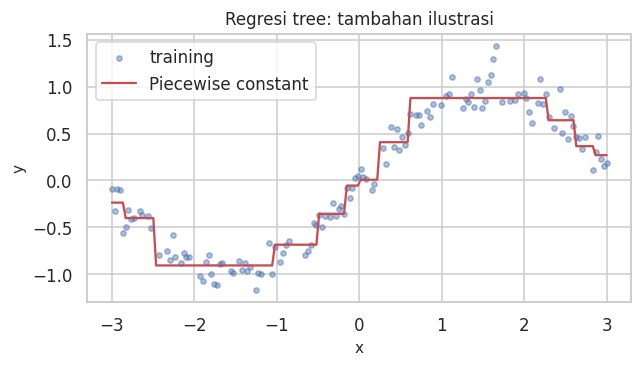

In [9]:
tree_search=GridSearchCV(Pipeline([("preprocess",preprocessing()),("model",DecisionTreeClassifier(random_state=SEED))]),
    {"model__max_depth":[3,6,None],"model__min_samples_leaf":[10,40]},scoring="average_precision",cv=cv,n_jobs=1)
tree_search.fit(X_train,y_train)
print("Tree dipilih training CV:",tree_search.best_params_,"AP:",round(tree_search.best_score_,4))
# Supplementary regression example: fixed depth chosen in advance, independent synthetic data.
x=np.linspace(-3,3,180).reshape(-1,1);y=np.sin(x[:,0])+rng.normal(0,.15,len(x))
xtr,xte,ytr,yte=train_test_split(x,y,test_size=.25,random_state=SEED)
reg_tree=DecisionTreeRegressor(max_depth=4,min_samples_leaf=5,random_state=SEED).fit(xtr,ytr)
reg_dummy=DummyRegressor().fit(xtr,ytr)
display(pd.DataFrame([{ "model":name,"test_MAE":mean_absolute_error(yte,m.predict(xte)),"test_R2":r2_score(yte,m.predict(xte))} for name,m in [("Tree regression",reg_tree),("Mean baseline",reg_dummy)]]))
fig,ax=plt.subplots(figsize=(6,3.5));ax.scatter(xtr[:,0],ytr,s=12,alpha=.45,label="training");ax.plot(x[:,0],reg_tree.predict(x),color="C3",label="Piecewise constant")
ax.set(xlabel="x",ylabel="y",title="Regresi tree: tambahan ilustrasi");ax.legend();plt.tight_layout();plt.show()

## 4. Bagging, random forest dan OOB

Bagging melatih model pada beberapa bootstrap sample (sampling dengan pengembalian), lalu merata-ratakan prediksi. Random forest menambah pengacakan subset fitur pada setiap split sehingga pohon lebih beragam. Averaging terutama mengurangi variance; ia tidak otomatis memperbaiki bias model yang salah.

Satu bootstrap berukuran n mengabaikan sekitar $e^{-1}\approx36,8\%$ observasi ketika n besar. Observasi *out-of-bag* (OOB) dapat dievaluasi oleh pohon yang tidak melihatnya. OOB membantu diagnosis tanpa memakai test, tetapi bila dipakai berulang untuk tuning, hasil terpilih tetap dapat optimistis. Preprocessing yang belajar dari seluruh data sebelum OOB juga dapat mengurangi isolasi; contoh OOB di bawah memakai dua numerik lengkap tanpa preprocessing terpelajar.

Hyperparameter utama: jumlah pohon mengendalikan stabilitas/waktu, `max_features` keragaman, `max_depth` dan `min_samples_leaf` kapasitas. Menambah pohon tidak sama dengan membuat setiap pohon lebih kompleks.

,trees,OOB_accuracy
0,50,0.609333
1,100,0.609000
2,200,0.613000


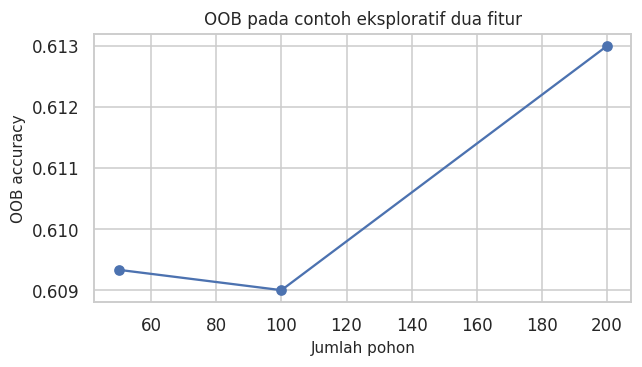

Bagging selesai: 80 pohon; prediksi contoh [[0.47  0.53 ]
 [0.463 0.537]
 [0.676 0.324]]
Random forest dipilih training CV: {'model__max_depth': 6, 'model__min_samples_leaf': 20} AP: 0.6718


In [10]:
oob_rows=[]
for n in [50,100,200]:
    rf_demo=RandomForestClassifier(n_estimators=n,max_depth=5,criterion="entropy",oob_score=True,random_state=SEED,n_jobs=1).fit(small[two],small.default)
    oob_rows.append({"trees":n,"OOB_accuracy":rf_demo.oob_score_})
display(pd.DataFrame(oob_rows))
fig,ax=plt.subplots(figsize=(6,3.5));ax.plot([r["trees"] for r in oob_rows],[r["OOB_accuracy"] for r in oob_rows],"o-")
ax.set(xlabel="Jumlah pohon",ylabel="OOB accuracy",title="OOB pada contoh eksploratif dua fitur")
plt.tight_layout();plt.show()
bag=BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=5,min_samples_leaf=10),n_estimators=80,random_state=SEED,n_jobs=1).fit(small[two],small.default)
print("Bagging selesai:",len(bag.estimators_),"pohon; prediksi contoh",bag.predict_proba(small[two].iloc[:3]).round(3))
rf_search=GridSearchCV(Pipeline([("preprocess",preprocessing()),("model",RandomForestClassifier(n_estimators=150,random_state=SEED,n_jobs=1))]),
    {"model__max_depth":[6,None],"model__min_samples_leaf":[5,20]},scoring="average_precision",cv=cv,n_jobs=1)
rf_search.fit(X_train,y_train)
print("Random forest dipilih training CV:",rf_search.best_params_,"AP:",round(rf_search.best_score_,4))

### 4.1 Variable importance

Impurity importance menjumlahkan penurunan impurity yang diberikan fitur. Ukuran ini cenderung menguntungkan fitur dengan banyak nilai/split yang mungkin. Gini dan entropy dapat menghasilkan ranking berbeda. Permutation importance mengacak satu fitur pada data evaluasi dan melihat penurunan skor; fitur berkorelasi dapat saling menggantikan sehingga kontribusinya terlihat kecil.

Kita mengacak **kolom asli** pada validation melalui pipeline, sehingga kelompok one-hot tetap diinterpretasikan sebagai satu fitur. Angka importance bukan efek kausal dan bukan p-value. Test tetap belum dipakai. Grafik impurity menampilkan fitur encoded; grafik permutation memakai fitur asli, sehingga magnitudonya tidak dapat dibandingkan langsung.

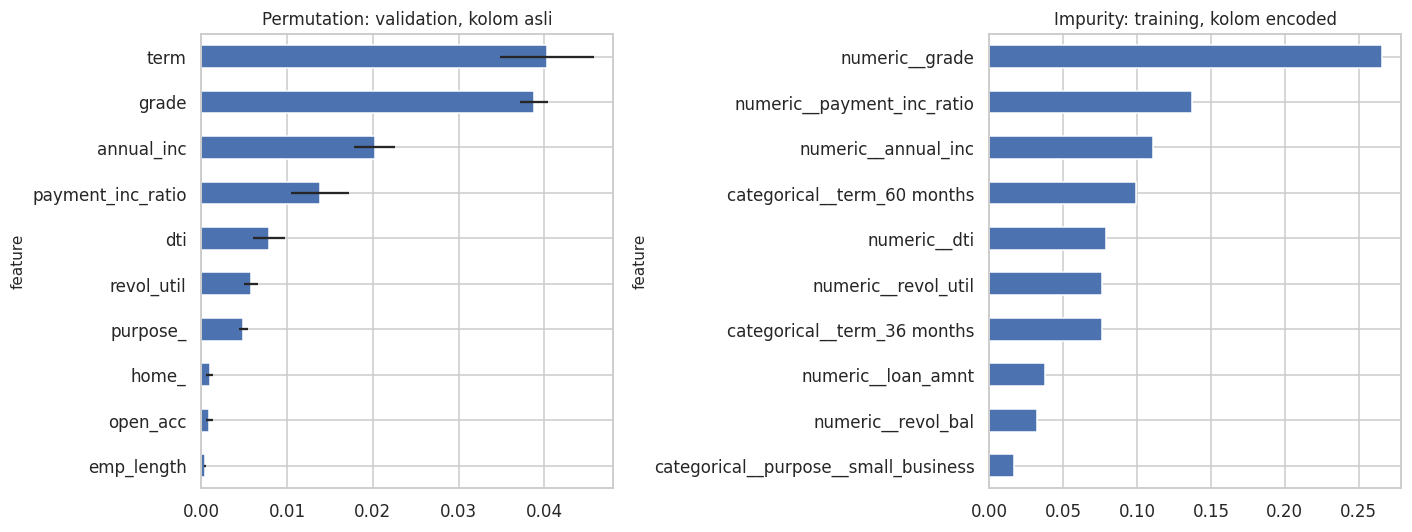

,feature,AP_decrease,std
11,term,0.0403,0.0055
9,grade,0.0388,0.0016
1,annual_inc,0.0202,0.0024
3,payment_inc_ratio,0.0138,0.0034
2,dti,0.0079,0.0019
5,revol_util,0.0058,0.0008
12,purpose_,0.0049,0.0005
13,home_,0.0010,0.0004


In [11]:
rf_best=rf_search.best_estimator_
perm=permutation_importance(rf_best,X_val,y_val,scoring="average_precision",n_repeats=3,random_state=SEED,n_jobs=1)
perm_df=pd.DataFrame({"feature":FEATURES,"AP_decrease":perm.importances_mean,"std":perm.importances_std}).sort_values("AP_decrease")
encoded_names=rf_best.named_steps["preprocess"].get_feature_names_out()
importance_df=pd.DataFrame({"feature":encoded_names,"Gini_decrease":rf_best.named_steps["model"].feature_importances_}).sort_values("Gini_decrease")
fig,axes=plt.subplots(1,2,figsize=(13,5))
perm_df.tail(10).plot.barh(x="feature",y="AP_decrease",xerr=perm_df.tail(10)["std"].to_numpy(),legend=False,ax=axes[0])
importance_df.tail(10).plot.barh(x="feature",y="Gini_decrease",legend=False,ax=axes[1])
axes[0].set_title("Permutation: validation, kolom asli");axes[1].set_title("Impurity: training, kolom encoded")
plt.tight_layout();plt.show()
display(perm_df.tail(8).iloc[::-1].round(4))

## 5. Boosting dan XGBoost

Boosting membangun model berurutan, dengan model baru memperbaiki kesalahan/gradien loss model gabungan saat ini:

$$F_m(x)=F_{m-1}(x)+\eta h_m(x).$$

Pada klasifikasi biner, skor additive dipetakan ke probabilitas melalui sigmoid. Gradient boosting mempelajari arah pengurangan loss; ia berbeda dari bagging yang membangun model lebih independen. XGBoost memakai turunan pertama/kedua dan penalti kompleksitas tree. `learning_rate` mengendalikan ukuran langkah; jumlah tree, kedalaman, subsampling baris/kolom, `reg_lambda` (L2) dan `reg_alpha` (L1) memengaruhi overfitting.

Pada target 0/1, **kolom probabilitas kelas 1 adalah default**. Beberapa contoh lama keliru memberi nama prob_default pada kolom kelas 0; notebook selalu memeriksa `classes_`. Kurva iterasi memakai `(0, m)`, sehingga tree pertama disertakan. Label validation tidak disebut test selama tuning.

,actual_default,P_default
0,0,0.486943
1,1,0.538134
2,0,0.351878
3,0,0.394514
4,1,0.619916


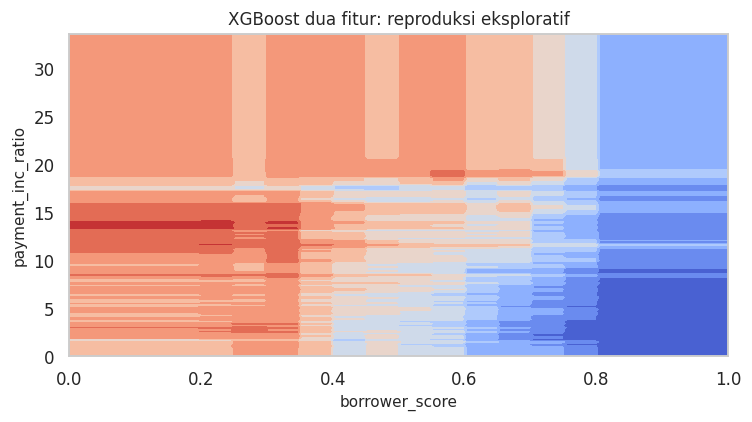

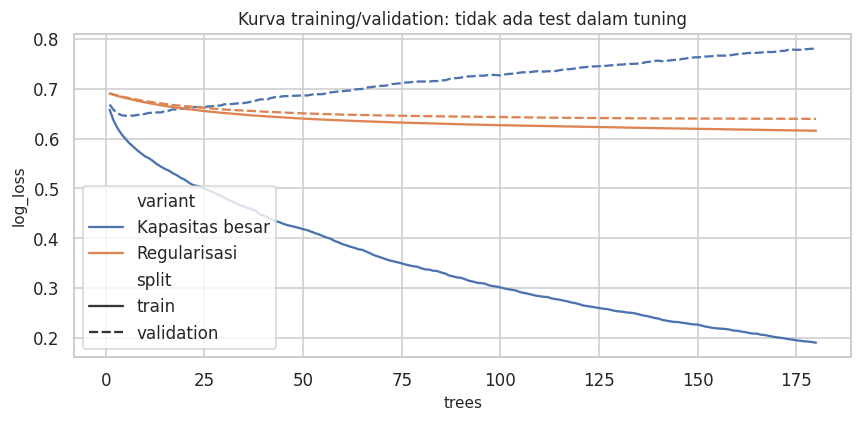

In [12]:
xgb_demo=XGBClassifier(n_estimators=120,max_depth=3,learning_rate=.1,subsample=.63,objective="binary:logistic",eval_metric="logloss",tree_method="hist",random_state=SEED,n_jobs=1).fit(small[two],small.default)
pos_idx=list(xgb_demo.classes_).index(1)
display(pd.DataFrame({"actual_default":small.default.iloc[:5],"P_default":xgb_demo.predict_proba(small[two].iloc[:5])[:,pos_idx]}))
fig,ax=plt.subplots(figsize=(7,4));ax.contourf(gx,gy,xgb_demo.predict_proba(grid)[:,pos_idx].reshape(gx.shape),levels=np.linspace(0,1,11),cmap="coolwarm")
ax.set(xlabel=two[0],ylabel=two[1],title="XGBoost dua fitur: reproduksi eksploratif")
plt.tight_layout();plt.show()
# Preprocessor is trained only on training; validation is merely transformed.
boost_pre=preprocessing().fit(X_train,y_train)
boost_train=boost_pre.transform(X_train);boost_val=boost_pre.transform(X_val)
boost_variants={
    "Kapasitas besar":dict(max_depth=6,learning_rate=.3,reg_lambda=0,subsample=1.),
    "Regularisasi":dict(max_depth=6,learning_rate=.1,reg_lambda=1000,subsample=.63)}
boost_curves=[]
for name,params in boost_variants.items():
    booster=XGBClassifier(n_estimators=180,objective="binary:logistic",eval_metric="logloss",tree_method="hist",random_state=SEED,n_jobs=1,**params)
    booster.fit(boost_train,y_train,eval_set=[(boost_train,y_train),(boost_val,y_val)],verbose=False)
    history=booster.evals_result()
    for part,key in [("train","validation_0"),("validation","validation_1")]:
        for i,loss in enumerate(history[key]["logloss"],1):boost_curves.append({"variant":name,"split":part,"trees":i,"log_loss":loss})
fig,ax=plt.subplots(figsize=(8,4));sns.lineplot(data=pd.DataFrame(boost_curves),x="trees",y="log_loss",hue="variant",style="split",ax=ax)
ax.set_title("Kurva training/validation: tidak ada test dalam tuning")
plt.tight_layout();plt.show()

### 5.1 Hyperparameter dan cross-validation

Pencarian berikut memakai stratified 3-fold CV pada training, dengan kedalaman 2/4 dan learning rate 0,05/0,15. Jumlah tree 180 ditetapkan sebelum hasil dilihat. Prosedur ini mengganti pembagian fold acak manual dan grid 9 kombinasi yang lebih mahal pada kode sumber. Pipeline memasang ulang preprocessing di setiap fold.

Skor CV terbaik tetap dapat optimistis akibat pemilihan dari beberapa kandidat. Validation membandingkan keluarga model yang telah dituning; final test memberikan evaluasi setelah pilihan dikunci. Repeated/nested CV dapat dipakai jika ketidakpastian model selection perlu dipelajari lebih jauh.

In [13]:
xgb_search=GridSearchCV(Pipeline([("preprocess",preprocessing()),("model",XGBClassifier(n_estimators=180,subsample=.8,colsample_bytree=.8,reg_lambda=1.,objective="binary:logistic",eval_metric="logloss",tree_method="hist",random_state=SEED,n_jobs=1))]),
    {"model__max_depth":[2,4],"model__learning_rate":[.05,.15]},cv=cv,scoring="average_precision",n_jobs=1)
xgb_search.fit(X_train,y_train)
display(pd.DataFrame(xgb_search.cv_results_)[["param_model__max_depth","param_model__learning_rate","mean_test_score","std_test_score"]])
print("XGBoost dipilih training CV:",xgb_search.best_params_)

,param_model__max_depth,param_model__learning_rate,mean_test_score,std_test_score
0,2,0.05,0.679784,0.010673
1,4,0.05,0.675957,0.011419
2,2,0.15,0.675315,0.013413
3,4,0.15,0.656145,0.008320


XGBoost dipilih training CV: {'model__learning_rate': 0.05, 'model__max_depth': 2}


## 6. Perbandingan validation dan final test

Model keluarga KNN/tree/forest/XGBoost dipilih melalui CV, sedangkan logistic baseline dan model dengan fitur KNN OOF mempunyai konfigurasi tetap. Semua dibandingkan pada validation yang sama menggunakan AP. Test hanya dievaluasi untuk pilihan akhir dan dummy baseline. Threshold 0,5 ditetapkan sejak awal; penyesuaian biaya memerlukan validation tersendiri seperti Chapter 5.

Accuracy, precision, recall dan F1 bergantung threshold. AUC/AP mengevaluasi ranking; log-loss menilai probabilitas dan sangat menghukum prediksi salah yang terlalu yakin. Dataset buku yang seimbang tidak menyamai prevalensi kredit dunia nyata. Perbandingan ini tidak merupakan rekomendasi keputusan kredit.

,validation_AP,validation_AUC,validation_logloss
model,,,
Logistic baseline,0.6719,0.6846,0.6387
XGBoost,0.6717,0.6852,0.6368
Random forest,0.6598,0.6798,0.6434
KNN,0.6393,0.6648,0.6513
Logistic + KNN OOF,0.6359,0.6655,0.6511
Decision tree,0.6299,0.6613,0.6981


Model terkunci sebelum test: Logistic baseline


,accuracy,balanced_accuracy,precision_default,recall_default,F1,AUC,AP,log_loss
Logistic baseline,0.6566,0.6566,0.6626,0.6381,0.6501,0.7142,0.698,0.6223
Dummy prior,0.5000,0.5000,0.5000,1.0000,0.6667,0.5000,0.500,0.6931


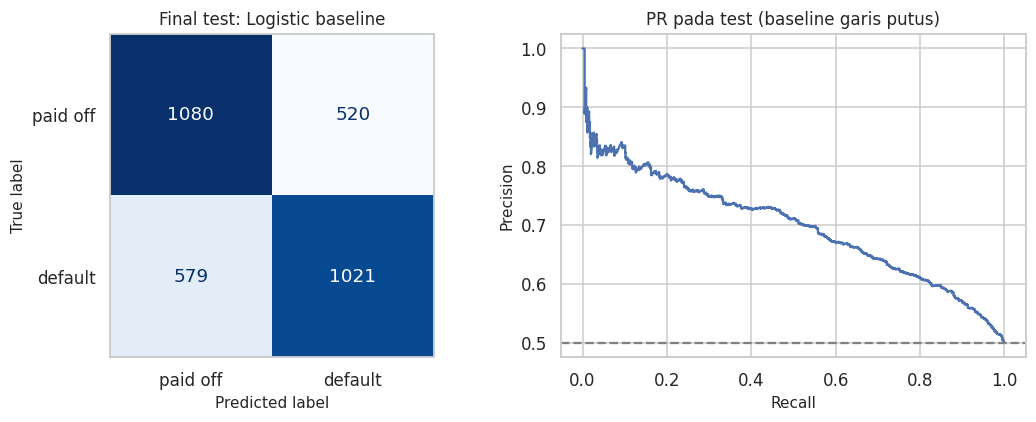

In [14]:
candidates={"KNN":knn_search.best_estimator_,"Decision tree":tree_search.best_estimator_,"Random forest":rf_search.best_estimator_,"XGBoost":xgb_search.best_estimator_}
logit_baseline=Pipeline([("preprocess",preprocessing(True)),("model",LogisticRegression(max_iter=2000))]).fit(X_train,y_train)
candidates["Logistic baseline"]=logit_baseline
validation_rows=[]
for name,m in candidates.items():
    pr=m.predict_proba(X_val)[:,1]
    validation_rows.append({"model":name,"validation_AP":average_precision_score(y_val,pr),"validation_AUC":roc_auc_score(y_val,pr),"validation_logloss":log_loss(y_val,pr)})
meta_p=meta.predict_proba(val_aug)[:,1]
validation_rows.append({"model":"Logistic + KNN OOF","validation_AP":average_precision_score(y_val,meta_p),"validation_AUC":roc_auc_score(y_val,meta_p),"validation_logloss":log_loss(y_val,meta_p)})
validation_results=pd.DataFrame(validation_rows).set_index("model").sort_values("validation_AP",ascending=False)
display(validation_results.round(4))
winner=validation_results.index[0]
print("Model terkunci sebelum test:",winner)
if winner=="Logistic + KNN OOF":
    test_aug=X_test[NUM].copy();test_aug["borrower_score_oof"]=1-engine.predict_proba(X_test[engine_cols])[:,1]
    final_p=meta.predict_proba(test_aug)[:,1]
else:final_p=candidates[winner].predict_proba(X_test)[:,1]
dummy=DummyClassifier(strategy="prior").fit(X_train,y_train)
def metrics(y,p):
    pred=np.asarray(p)>=.5
    return {"accuracy":accuracy_score(y,pred),"balanced_accuracy":balanced_accuracy_score(y,pred),"precision_default":precision_score(y,pred,zero_division=0),"recall_default":recall_score(y,pred),"F1":f1_score(y,pred),"AUC":roc_auc_score(y,p),"AP":average_precision_score(y,p),"log_loss":log_loss(y,p)}
final_results=pd.DataFrame({winner:metrics(y_test,final_p),"Dummy prior":metrics(y_test,dummy.predict_proba(X_test)[:,1])}).T
display(final_results.round(4))
fig,axes=plt.subplots(1,2,figsize=(10,4))
ConfusionMatrixDisplay.from_predictions(y_test,final_p>=.5,display_labels=["paid off","default"],ax=axes[0],colorbar=False,cmap="Blues")
axes[0].grid(False)
axes[0].set_title("Final test: "+winner)
pr,re,_=precision_recall_curve(y_test,final_p);axes[1].plot(re,pr);axes[1].axhline(y_test.mean(),ls="--",color="gray")
axes[1].set(xlabel="Recall",ylabel="Precision",title="PR pada test (baseline garis putus)")
plt.tight_layout();plt.show()

## Analisis hasil eksekusi yang disertakan

- Pada loan200, voting 20 tetangga memprediksi paid off dengan proporsi **0,55**. Baris target tidak memiliki label aktual; tidak ada akurasi yang bisa dihitung untuk baris itu.
- Dari lima tetangga contoh standardisasi, **tidak ada tetangga yang sama** antara ruang mentah dan standar. Tanpa scaling, nilai revol_bal mendominasi kedekatan. Perubahan ini menunjukkan bahwa jarak mencerminkan pilihan satuan.
- Fitur KNN OOF hanya mengubah AP validation logistic numerik dari sekitar **0,6357** ke **0,6359**. Kenaikan kecil ini tidak membuktikan manfaat universal. Fitur tambahan bukan jaminan peningkatan berarti.
- OOB pada demonstrasi dua fitur sekitar **60,9–61,3%**. Ini hasil eksploratif yang masih memakai borrower_score sumber; bukan skor generalisasi benchmark utama.
- Pada kurva boosting, model kapasitas besar terus menurunkan log-loss training sementara validation memburuk. Konfigurasi regularisasi menjaga selisih lebih kecil. Ini contoh konkret overfitting, bukan alasan memilih model dari test.
- AP validation memilih **Logistic baseline (0,6719)**, sangat dekat dengan **XGBoost (0,6717)**. Perbedaan 0,0002 pada satu split terlalu kecil untuk menyimpulkan satu algoritme pasti lebih baik.
- Model terpilih menghasilkan **akurasi test 65,66%**, **AUC 0,7142**, **AP 0,6980**, dan log-loss **0,6223**, dibanding dummy AUC/AP 0,5 dan log-loss 0,6931. Recall default sekitar **63,81%**. Dummy selalu-positif dapat memiliki F1 lebih tinggi pada sampel seimbang, tetapi specificity-nya nol; satu metrik tidak mewakili seluruh tujuan.

Interpretasi ini mengikuti run yang disertakan pada 10 Oktober 2026 (WIB). Tidak ada pengubahan model setelah membaca test.

## Ringkasan chapter

KNN bergantung pada jarak, scaling, dan pilihan k. Fitur yang diturunkan dari label memerlukan cross-fitting. Tree membagi ruang fitur dengan penurunan impurity; pembatasan pertumbuhan menyeimbangkan bias dan variance. Bagging/forest merata-ratakan model bootstrap, sementara boosting memperbaiki model secara berurutan. OOB, CV, dan validation membantu pengembangan, tetapi test tetap disimpan untuk evaluasi akhir. Importance merupakan sifat model dan data, bukan hubungan sebab-akibat. Random seed, distribusi kelas, dan batas representativitas harus dilaporkan bersama skor.

## Refleksi mandiri

Jawab berdasarkan output dan pemahaman Anda; jangan sekadar menyalin rangkuman.

1. Berapa tetangga yang berubah setelah standardisasi, dan fitur apa yang menjelaskan perubahan tersebut?
2. Mengapa prediksi KNN pada training sendiri tidak boleh langsung dipakai sebagai fitur evaluasi?
3. Bandingkan ranking Gini dan permutation importance. Bagaimana korelasi fitur memengaruhi interpretasinya?
4. Apa yang ditunjukkan selisih log-loss training dan validation pada dua konfigurasi boosting?
5. Model mana yang dipilih validation, dan bagaimana skor testnya dibanding dummy? Mengapa test tidak boleh dipakai memilih ulang?

## Referensi

1. Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists*, 2nd ed. O’Reilly Media.
2. [Kode pendamping resmi dan lisensi](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/8a6d3bb6468e979c861d4b37215e1413702dfdfa). Cakupan diverifikasi melalui kode chapter resmi; PDF pada tautan tugas tidak dapat dibaca melalui akses yang tersedia.
3. [Kode resmi Chapter 6](https://github.com/gedeck/practical-statistics-for-data-scientists/blob/8a6d3bb6468e979c861d4b37215e1413702dfdfa/python/code/Chapter%206%20-%20Statistical%20Machine%20Learning.py).
4. [scikit-learn: nearest neighbors](https://scikit-learn.org/stable/modules/neighbors.html).
5. [scikit-learn: decision trees](https://scikit-learn.org/stable/modules/tree.html).
6. [scikit-learn: ensemble methods](https://scikit-learn.org/stable/modules/ensemble.html).
7. [scikit-learn: permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).
8. [XGBoost Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html).